▶️ Calcul lancé...

==================== RÉSULTATS ====================
Iterations: 50,000
P(gagner) : 87.69%
P(split)  : 0.00%
P(perdre) : 12.31%

--- TOI (meilleure main sur 7 cartes) ---
 Straight Flush :   4.29%
 Four of a Kind :   0.00%
     Full House :   0.00%
          Flush :  95.71%
       Straight :   0.00%
Three of a Kind :   0.00%
       Two Pair :   0.00%
       One Pair :   0.00%
      High Card :   0.00%

--- ADVERSAIRE typique (1 joueur aléatoire) ---
 Straight Flush :   0.00%
 Four of a Kind :   0.08%
     Full House :   1.63%
          Flush :  12.92%
       Straight :   5.54%
Three of a Kind :   3.69%
       Two Pair :  19.49%
       One Pair :  39.57%
      High Card :  17.08%

--- MEILLEUR adversaire (max parmi N) ---
 Straight Flush :   0.01%
 Four of a Kind :   0.32%
     Full House :   5.65%
          Flush :  31.47%
       Straight :  12.68%
Three of a Kind :   7.80%
       Two Pair :  23.60%
       One Pair :  18.03%
      High Card :   0.45%

--- Événements 

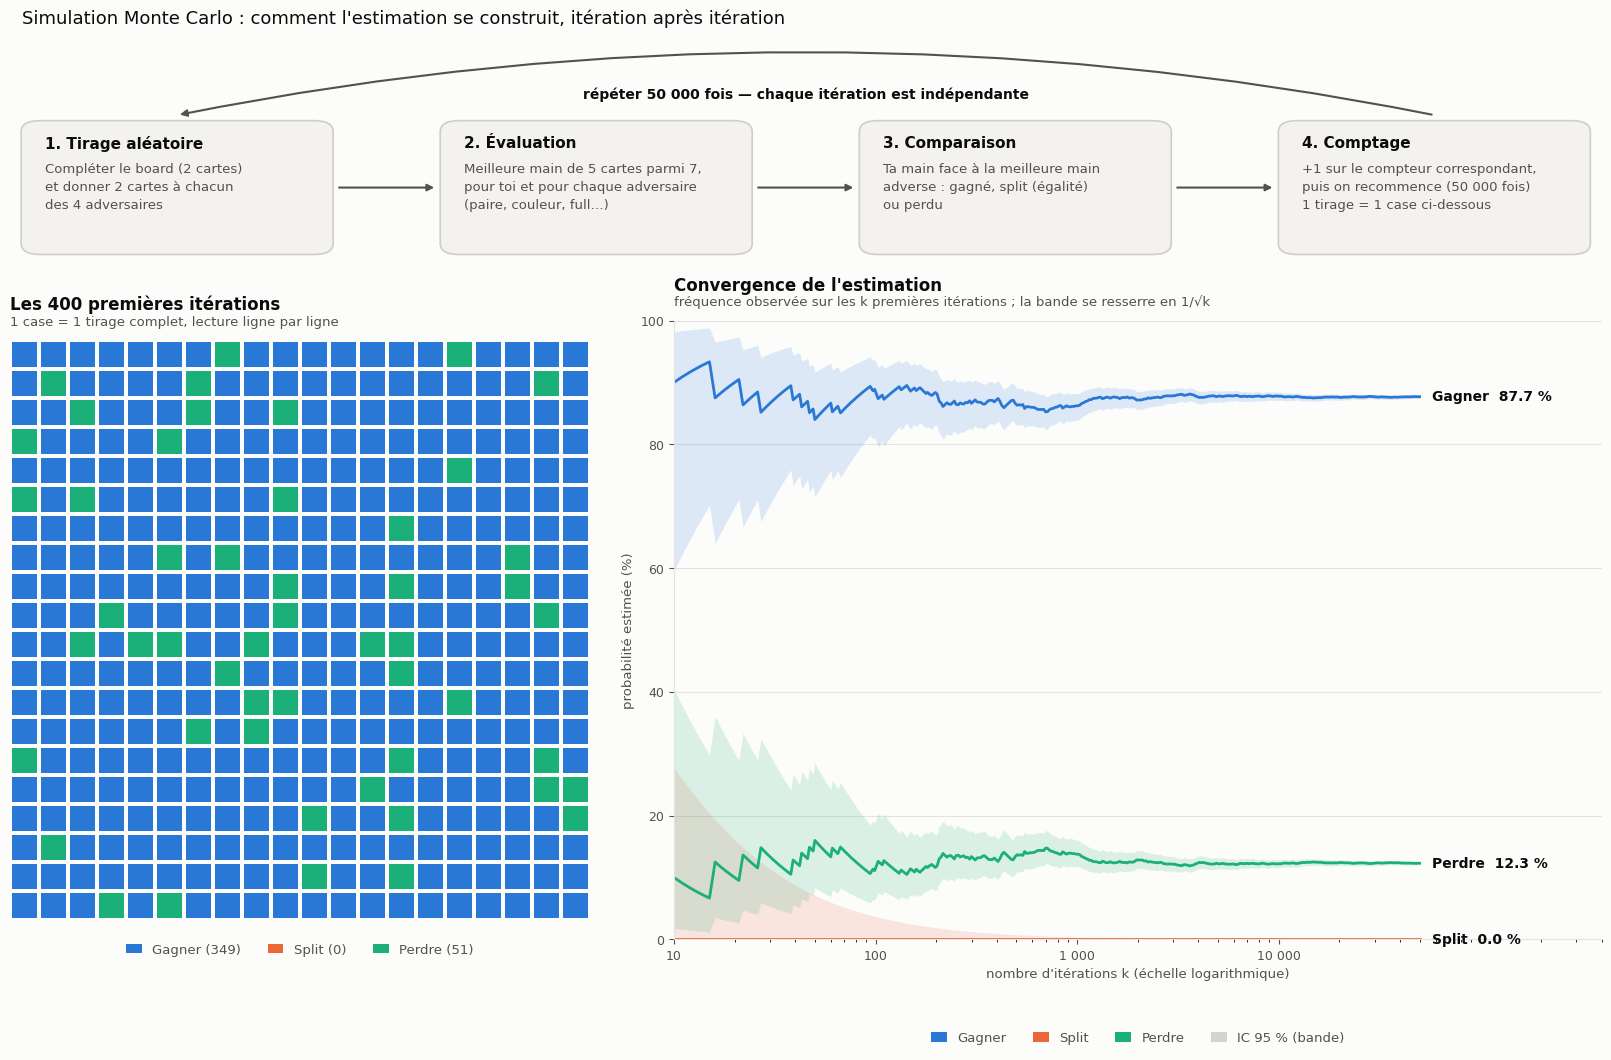

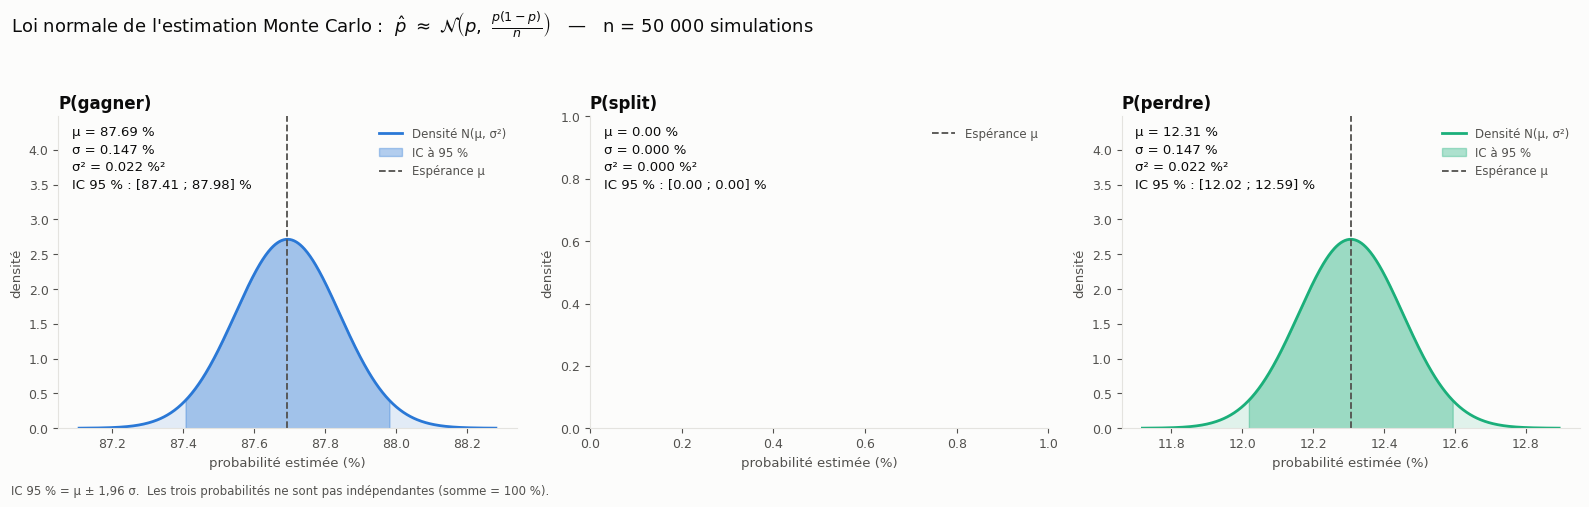

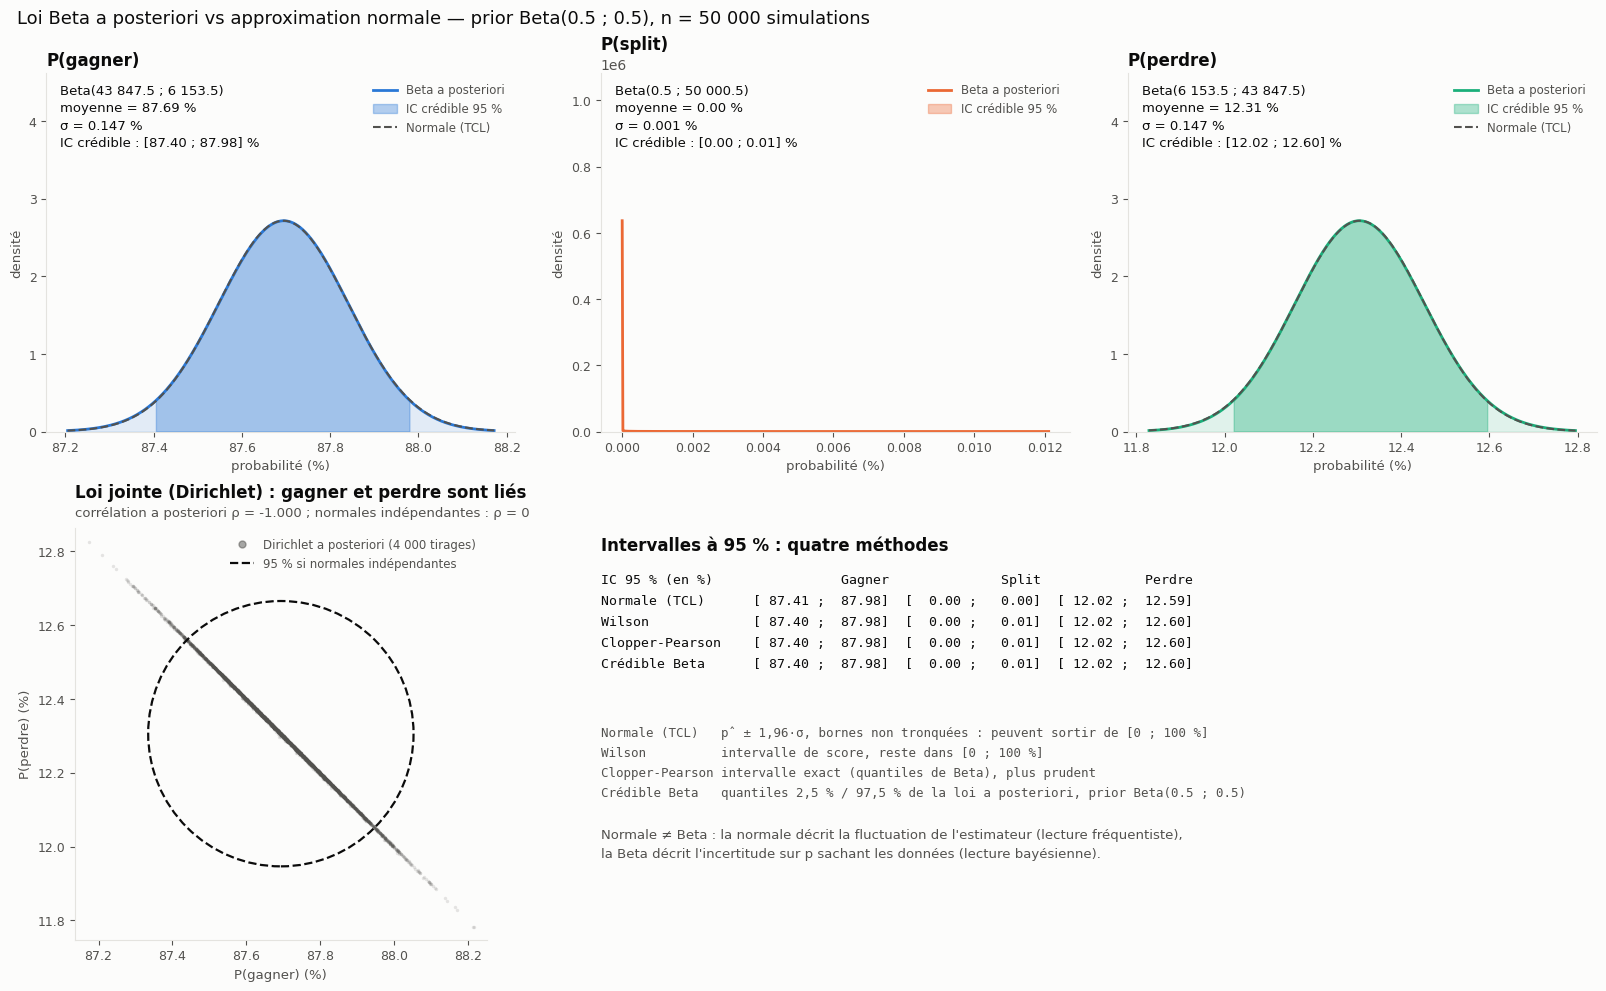

✅ Calcul terminé


In [4]:
import math
import random
import itertools
from collections import Counter
from dataclasses import dataclass

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta as beta_dist

# ============================================================
# CONFIG / CONSTANTS
# ============================================================
RANKS = "23456789TJQKA"
SUITS = "shdc"  # spades, hearts, diamonds, clubs
RANK_TO_INT = {r: i for i, r in enumerate(RANKS, start=2)}

CATEGORY_NAME = {
    8: "Straight Flush",
    7: "Four of a Kind",
    6: "Full House",
    5: "Flush",
    4: "Straight",
    3: "Three of a Kind",
    2: "Two Pair",
    1: "One Pair",
    0: "High Card",
}

# ============================================================
# CARD UTILS
# ============================================================
def build_deck():
    return [r + s for r in RANKS for s in SUITS]

def parse_cards(s: str):
    """
    Accepts:
      - "As Kd"
      - "AsKd"
      - "As, Kd"
      - "" (empty) -> []
    Note: removes quotes if user types them.
    """
    s = s.replace(",", " ").replace(";", " ").strip()
    if not s:
        return []
    parts = s.split()
    if len(parts) == 1 and len(parts[0]) % 2 == 0:
        raw = parts[0]
        parts = [raw[i:i+2] for i in range(0, len(raw), 2)]
    cards = []
    for c in parts:
        c = c.strip().replace("'", "").replace('"', "")
        if len(c) != 2:
            raise ValueError(f"Carte invalide: '{c}'. Format: As Td 2h etc.")
        r, suit = c[0].upper(), c[1].lower()
        if r not in RANKS or suit not in SUITS:
            raise ValueError(f"Carte invalide: '{c}'. Ranks={RANKS}, Suits={SUITS}")
        cards.append(r + suit)
    return cards

def card_rank(card: str) -> int:
    return RANK_TO_INT[card[0]]

def validate_no_duplicates(*groups):
    allc = []
    for g in groups:
        allc.extend(g)
    if len(set(allc)) != len(allc):
        raise ValueError("Cartes dupliquées détectées (main/board).")

# ============================================================
# HAND EVALUATION
# ============================================================
@dataclass(frozen=True)
class HandValue:
    category: int
    tiebreak: tuple  # lexicographic compare (higher is better)

def is_straight(ranks):
    uniq = sorted(set(ranks), reverse=True)
    if len(uniq) != 5:
        return (False, None)
    high = uniq[0]
    # Normal straight
    if uniq == list(range(high, high - 5, -1)):
        return (True, high)
    # Wheel A2345
    if uniq == [14, 5, 4, 3, 2]:
        return (True, 5)
    return (False, None)

def evaluate_5(cards5):
    ranks = sorted([card_rank(c) for c in cards5], reverse=True)
    suits = [c[1] for c in cards5]
    cnt = Counter(ranks)

    items = sorted(cnt.items(), key=lambda x: (x[1], x[0]), reverse=True)
    freqs = sorted(cnt.values(), reverse=True)

    flush = len(set(suits)) == 1
    straight, straight_high = is_straight(ranks)

    if flush and straight:
        return HandValue(8, (straight_high,))
    if freqs == [4, 1]:
        quad = items[0][0]; kicker = items[1][0]
        return HandValue(7, (quad, kicker))
    if freqs == [3, 2]:
        trips = items[0][0]; pair = items[1][0]
        return HandValue(6, (trips, pair))
    if flush:
        return HandValue(5, tuple(ranks))
    if straight:
        return HandValue(4, (straight_high,))
    if freqs == [3, 1, 1]:
        trips = items[0][0]
        kickers = sorted([r for r, f in items[1:]], reverse=True)
        return HandValue(3, (trips, *kickers))
    if freqs == [2, 2, 1]:
        p1 = items[0][0]; p2 = items[1][0]
        high_pair, low_pair = max(p1, p2), min(p1, p2)
        kicker = items[2][0]
        return HandValue(2, (high_pair, low_pair, kicker))
    if freqs == [2, 1, 1, 1]:
        pair = items[0][0]
        kickers = sorted([r for r, f in items[1:]], reverse=True)
        return HandValue(1, (pair, *kickers))
    return HandValue(0, tuple(ranks))

def best_of_7(cards7):
    best = None
    for combo in itertools.combinations(cards7, 5):
        hv = evaluate_5(combo)
        if best is None or (hv.category, hv.tiebreak) > (best.category, best.tiebreak):
            best = hv
    return best

# ============================================================
# MONTE CARLO (multiway) + distributions
# ============================================================
def estimate_multiway(hero_hole, board=None, n_opponents=5, iterations=300_000, seed=None):
    if seed is not None:
        random.seed(seed)

    board = board or []
    if len(hero_hole) != 2:
        raise ValueError("Tes 2 cartes doivent contenir exactement 2 cartes.")
    if len(board) > 5:
        raise ValueError("Board doit contenir entre 0 et 5 cartes.")

    validate_no_duplicates(hero_hole, board)

    deck = [c for c in build_deck() if c not in set(hero_hole + board)]
    unknown_board = 5 - len(board)
    if len(deck) < unknown_board + 2 * n_opponents:
        raise ValueError("Pas assez de cartes restantes pour cette configuration.")

    wins = ties = losses = 0
    outcomes = np.empty(iterations, dtype=np.int8)  # +1 gagné, 0 split, -1 perdu

    hero_cat = Counter()
    opp_best_cat = Counter()     # best hand among all opponents
    opp_typical_cat = Counter()  # first sampled opponent each run

    for it in range(iterations):
        sample = random.sample(deck, unknown_board + 2 * n_opponents)
        run_board = board + sample[:unknown_board]
        idx = unknown_board

        hero_best = best_of_7(hero_hole + run_board)
        hero_tuple = (hero_best.category, hero_best.tiebreak)
        hero_cat[hero_best.category] += 1

        best_opp_tuple = None
        best_opp_category = None

        typical_category = None

        for k in range(n_opponents):
            opp_hole = [sample[idx], sample[idx + 1]]
            idx += 2

            opp_best = best_of_7(opp_hole + run_board)
            opp_tuple = (opp_best.category, opp_best.tiebreak)

            if k == 0:
                typical_category = opp_best.category
                opp_typical_cat[typical_category] += 1

            if best_opp_tuple is None or opp_tuple > best_opp_tuple:
                best_opp_tuple = opp_tuple
                best_opp_category = opp_best.category

        opp_best_cat[best_opp_category] += 1

        if hero_tuple > best_opp_tuple:
            wins += 1
            outcomes[it] = 1
        elif hero_tuple < best_opp_tuple:
            losses += 1
            outcomes[it] = -1
        else:
            ties += 1
            outcomes[it] = 0

    total = wins + ties + losses
    hero_dist = {cat: hero_cat.get(cat, 0) / total for cat in range(8, -1, -1)}
    opp_typical_dist = {cat: opp_typical_cat.get(cat, 0) / total for cat in range(8, -1, -1)}
    opp_best_dist = {cat: opp_best_cat.get(cat, 0) / total for cat in range(8, -1, -1)}

    return {
        "iterations": total,
        "p_win": wins / total,
        "p_tie": ties / total,
        "p_lose": losses / total,
        "hero_hand_distribution": hero_dist,
        "opp_typical_distribution": opp_typical_dist,
        "opp_best_distribution": opp_best_dist,
        "outcomes": outcomes,
        "n_opponents": n_opponents,
        "n_board_unknown": unknown_board,
    }

# ============================================================
# DISPLAY
# ============================================================
# --- Style des graphiques (mêmes couleurs partout : une couleur = une issue) ---
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
COLORS = {"Gagner": "#2a78d6", "Split": "#eb6834", "Perdre": "#1baf7a"}

def normal_summary(res):
    """
    Loi normale de l'estimation Monte Carlo (théorème central limite).

    Chaque simulation est un tirage de Bernoulli (ex : gagné / pas gagné), donc le nombre
    de succès sur n simulations suit une Binomiale(n, p). Pour n grand, la fréquence
    observée p̂ suit approximativement :

        p̂ ~ N( espérance μ = p ,  variance σ² = p(1 - p) / n )

    (on remplace le vrai p, inconnu, par la fréquence observée p̂).
    Valeurs renvoyées en proportions (0-1), sauf indication contraire.
    """
    n = res["iterations"]
    out = {}
    for key, name in (("p_win", "Gagner"), ("p_tie", "Split"), ("p_lose", "Perdre")):
        p = res[key]
        var = p * (1 - p) / n
        sigma = math.sqrt(var)
        out[name] = {
            "mu": p,
            "var": var,
            "sigma": sigma,
            "ci_low": max(0.0, p - 1.96 * sigma),
            "ci_high": min(1.0, p + 1.96 * sigma),
        }
    return out

def beta_summary(res, prior=(0.5, 0.5)):
    """
    Loi a posteriori de p (approche bayésienne) pour chaque issue.

    Modèle : le nombre de succès c sur n simulations suit Binomiale(n, p).
    Avec un prior Beta(a0, b0) sur p (par défaut Jeffreys : a0 = b0 = 1/2), la loi a posteriori
    est conjuguée, donc EXACTE (aucune hypothèse « n grand ») :

        p | données ~ Beta(a0 + c, b0 + n - c)

    Pour les trois issues ensemble (multinomiale), c'est une Dirichlet(a0 + c_gagné, a0 + c_split,
    a0 + c_perdu) dont chaque loi marginale est une Beta. Valeurs en proportions (0-1).
    """
    n = res["iterations"]
    a0, b0 = prior
    out = {}
    for key, name in (("p_win", "Gagner"), ("p_tie", "Split"), ("p_lose", "Perdre")):
        c = int(round(res[key] * n))
        a, b = a0 + c, b0 + n - c
        var = a * b / ((a + b) ** 2 * (a + b + 1))
        out[name] = {
            "count": c, "a": a, "b": b,
            "mean": a / (a + b), "var": var, "sd": math.sqrt(var),
            "cred_low": float(beta_dist.ppf(0.025, a, b)),
            "cred_high": float(beta_dist.ppf(0.975, a, b)),
        }
    return out

def interval_comparison(res, prior=(0.5, 0.5)):
    """
    Intervalle à 95 % de chaque issue par quatre méthodes -> {méthode: {issue: (bas, haut)}}.
      - Normale (TCL)   : p̂ ± 1,96 σ   (borne NON tronquée : peut sortir de [0 ; 1])
      - Wilson          : intervalle de score
      - Clopper-Pearson : intervalle exact (quantiles de Beta), prudent
      - Crédible Beta   : quantiles 2,5 % / 97,5 % de la loi a posteriori
    """
    n = res["iterations"]
    z = 1.96
    normal, post = normal_summary(res), beta_summary(res, prior)
    table = {"Normale (TCL)": {}, "Wilson": {}, "Clopper-Pearson": {}, "Crédible Beta": {}}
    for name, s in post.items():
        c = s["count"]
        p = c / n
        centre = (p + z * z / (2 * n)) / (1 + z * z / n)
        half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
        table["Normale (TCL)"][name] = (p - z * normal[name]["sigma"], p + z * normal[name]["sigma"])
        table["Wilson"][name] = (max(0.0, centre - half), min(1.0, centre + half))
        table["Clopper-Pearson"][name] = (
            0.0 if c == 0 else float(beta_dist.ppf(0.025, c, n - c + 1)),
            1.0 if c == n else float(beta_dist.ppf(0.975, c + 1, n - c)),
        )
        table["Crédible Beta"][name] = (s["cred_low"], s["cred_high"])
    return table

def format_interval_table(res, prior=(0.5, 0.5)):
    """Tableau texte (en %) des intervalles à 95 % : une ligne par méthode, une colonne par issue."""
    table = interval_comparison(res, prior)
    names = ["Gagner", "Split", "Perdre"]
    lines = [f"{'IC 95 % (en %)':<17}" + "".join(f"{nm:>19}" for nm in names)]
    for method, row in table.items():
        cells = "".join(
            f"{f'[{100 * row[nm][0]:6.2f} ; {100 * row[nm][1]:6.2f}]':>19}" for nm in names
        )
        lines.append(f"{method:<17}{cells}")
    return "\n".join(lines)

def print_distribution(title, dist):
    print(f"\n--- {title} ---")
    for cat in range(8, -1, -1):
        p = dist.get(cat, 0.0)
        print(f"{CATEGORY_NAME[cat]:>15} : {100*p:6.2f}%")

def print_results(res):
    print("\n==================== RÉSULTATS ====================")
    print(f"Iterations: {res['iterations']:,}")
    print(f"P(gagner) : {100*res['p_win']:.2f}%")
    print(f"P(split)  : {100*res['p_tie']:.2f}%")
    print(f"P(perdre) : {100*res['p_lose']:.2f}%")

    print_distribution("TOI (meilleure main sur 7 cartes)", res["hero_hand_distribution"])
    print_distribution("ADVERSAIRE typique (1 joueur aléatoire)", res["opp_typical_distribution"])
    print_distribution("MEILLEUR adversaire (max parmi N)", res["opp_best_distribution"])

    hero = res["hero_hand_distribution"]
    oppB = res["opp_best_distribution"]
    print("\n--- Événements (au moins) ---")
    print(f"Toi:   P(Suite ou mieux) : {100*sum(hero[c] for c in range(4, 9)):.2f}%")
    print(f"Toi:   P(Flush ou mieux) : {100*sum(hero[c] for c in range(5, 9)):.2f}%")
    print(f"Table: P(Suite+ chez le meilleur adversaire) : {100*sum(oppB[c] for c in range(4, 9)):.2f}%")
    print(f"Table: P(Flush+ chez le meilleur adversaire) : {100*sum(oppB[c] for c in range(5, 9)):.2f}%")

    print("\n--- Loi normale de l'estimation (TCL) : p̂ ~ N(μ, σ²) ---")
    for name, s in normal_summary(res).items():
        print(
            f"{name:>8} : μ = {100*s['mu']:6.2f}%   σ = {100*s['sigma']:.3f}%   "
            f"σ² = {1e4*s['var']:.3f} %²   IC95% = [{100*s['ci_low']:.2f}% ; {100*s['ci_high']:.2f}%]"
        )

    print("\n--- Loi Beta a posteriori (prior de Jeffreys Beta(0.5 ; 0.5)) : p | données ~ Beta(a, b) ---")
    for name, s in beta_summary(res).items():
        a_txt = f"{s['a']:,.1f}".replace(",", " ")
        b_txt = f"{s['b']:,.1f}".replace(",", " ")
        print(
            f"{name:>8} : Beta({a_txt} ; {b_txt})   moyenne = {100*s['mean']:6.2f}%   "
            f"σ = {100*s['sd']:.3f}%   IC crédible 95% = [{100*s['cred_low']:.2f}% ; {100*s['cred_high']:.2f}%]"
        )

    print("\n--- Intervalles à 95 % : comparaison des méthodes ---")
    print(format_interval_table(res))
    print("===================================================\n")

def plot_normal_distributions(res, save_path=None):
    """
    Trace la loi normale N(μ, σ²) de l'estimation de P(gagner), P(split) et P(perdre),
    avec l'espérance μ (trait pointillé), l'écart-type σ, la variance σ² et l'IC à 95 %.
    """
    stats = normal_summary(res)
    n = res["iterations"]

    fig, axes = plt.subplots(1, 3, figsize=(16, 5), facecolor=SURFACE)
    for ax, (name, s) in zip(axes, stats.items()):
        color = COLORS[name]
        mu, sigma = 100 * s["mu"], 100 * s["sigma"]       # en %
        var_pct2 = 100 * 100 * s["var"]                   # en %²
        lo, hi = 100 * s["ci_low"], 100 * s["ci_high"]

        ax.set_facecolor(SURFACE)
        if sigma > 0:
            x = np.linspace(max(0.0, mu - 4 * sigma), min(100.0, mu + 4 * sigma), 600)
            y = np.exp(-0.5 * ((x - mu) / sigma) ** 2) / (sigma * math.sqrt(2 * math.pi))
            ax.plot(x, y, color=color, lw=2, label="Densité N(μ, σ²)")
            ax.fill_between(x, y, color=color, alpha=0.12)
            inside = (x >= lo) & (x <= hi)
            ax.fill_between(x[inside], y[inside], color=color, alpha=0.35, label="IC à 95 %")
            ax.set_ylim(0, 1.65 * y.max())
        else:  # p = 0 ou 1 : variance nulle, la "cloche" est un pic
            ax.set_xlim(max(0.0, mu - 1), min(100.0, mu + 1))
            ax.set_ylim(0, 1)
        ax.axvline(mu, color=INK2, lw=1.3, ls="--", label="Espérance μ")

        ax.text(
            0.03, 0.97,
            f"μ = {mu:.2f} %\n"
            f"σ = {sigma:.3f} %\n"
            f"σ² = {var_pct2:.3f} %²\n"
            f"IC 95 % : [{lo:.2f} ; {hi:.2f}] %",
            transform=ax.transAxes, ha="left", va="top", fontsize=9.5, color=INK,
            linespacing=1.45,
        )
        ax.legend(loc="upper right", frameon=False, fontsize=8.5, labelcolor=INK2)

        ax.set_title(f"P({name.lower()})", loc="left", fontsize=12, fontweight="bold", color=INK)
        ax.set_xlabel("probabilité estimée (%)", color=INK2, fontsize=9.5)
        ax.set_ylabel("densité", color=INK2, fontsize=9.5)
        ax.tick_params(colors=INK2, labelsize=9)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color(GRID)

    fig.suptitle(
        "Loi normale de l'estimation Monte Carlo :  "
        + r"$\hat{p}\ \approx\ \mathcal{N}\left(p,\ \frac{p(1-p)}{n}\right)$"
        + f"   —   n = {n:,} simulations".replace(",", " "),
        fontsize=13, color=INK, x=0.01, ha="left",
    )
    fig.text(
        0.01, 0.005,
        "IC 95 % = μ ± 1,96 σ.  Les trois probabilités ne sont pas indépendantes (somme = 100 %).",
        fontsize=8.5, color=INK2, ha="left", va="bottom",
    )
    fig.tight_layout(rect=(0, 0.03, 1, 0.93))
    if save_path:
        fig.savefig(save_path, dpi=150, facecolor=SURFACE)
    plt.show()


def plot_montecarlo_iterations(res, n_grid=400, cols=20, save_path=None):
    """
    Schéma de la simulation Monte Carlo :
      - en haut   : ce que fait UNE itération (tirage -> évaluation -> comparaison -> comptage)
      - à gauche  : les premières itérations, 1 case = 1 tirage (gagné / split / perdu)
      - à droite  : convergence de l'estimation quand le nombre d'itérations k augmente
                    (bande = IC 95 % de Wilson, qui se resserre en 1/√k)
    """
    from matplotlib.patches import FancyBboxPatch, Patch
    from matplotlib.colors import ListedColormap
    from matplotlib.ticker import FuncFormatter, NullFormatter

    out = np.asarray(res["outcomes"])          # +1 gagné, 0 split, -1 perdu (1 valeur / itération)
    n = len(out)
    n_txt = f"{n:,}".replace(",", " ")      # 5 000 (séparateur à la française)
    n_opp = res["n_opponents"]
    n_unknown = res["n_board_unknown"]

    fig = plt.figure(figsize=(16, 10.5), facecolor=SURFACE, constrained_layout=True)
    gs = fig.add_gridspec(2, 2, height_ratios=[1.0, 2.7], width_ratios=[1, 1.6])

    # ------------------------------------------------ 1) schéma d'UNE itération
    axf = fig.add_subplot(gs[0, :])
    axf.set_xlim(0, 100)
    axf.set_ylim(0, 25)
    axf.axis("off")

    board_txt = (f"Compléter le board ({n_unknown} carte{'s' if n_unknown > 1 else ''})"
                 if n_unknown else "Board déjà complet")
    opp_txt = (f"et donner 2 cartes à chacun\ndes {n_opp} adversaires" if n_opp > 1
               else "et donner 2 cartes\nà l'adversaire")
    steps = [
        ("1. Tirage aléatoire",
         f"{board_txt}\n{opp_txt}"),
        ("2. Évaluation",
         "Meilleure main de 5 cartes parmi 7,\npour toi et pour chaque adversaire\n(paire, couleur, full…)"),
        ("3. Comparaison",
         "Ta main face à la meilleure main\nadverse : gagné, split (égalité)\nou perdu"),
        ("4. Comptage",
         f"+1 sur le compteur correspondant,\npuis on recommence ({n_txt} fois)\n1 tirage = 1 case ci-dessous"),
    ]
    w, gap, y0, h = 19.0, 7.33, 1.5, 14.0
    for i, (title, body) in enumerate(steps):
        x0 = 1.0 + i * (w + gap)
        axf.add_patch(FancyBboxPatch(
            (x0, y0), w, h, boxstyle="round,pad=0.3,rounding_size=1.2",
            facecolor="#f3f2ee", edgecolor="#cfcdc6", linewidth=1.2))
        axf.text(x0 + 1.2, y0 + h - 1.3, title, ha="left", va="top",
                 fontsize=11, fontweight="bold", color=INK)
        axf.text(x0 + 1.2, y0 + h - 4.3, body, ha="left", va="top",
                 fontsize=9.5, color=INK2, linespacing=1.5)
        if i < 3:
            axf.annotate("", xy=(x0 + w + gap - 0.5, y0 + h / 2), xytext=(x0 + w + 0.5, y0 + h / 2),
                         arrowprops=dict(arrowstyle="-|>", color=INK2, lw=1.5))
    # flèche de boucle : de l'étape 4 vers l'étape 1
    x_first, x_last = 1.0 + w / 2, 1.0 + 3 * (w + gap) + w / 2
    axf.annotate("", xy=(x_first, y0 + h + 0.9), xytext=(x_last, y0 + h + 0.9),
                 arrowprops=dict(arrowstyle="-|>", color=INK2, lw=1.5, connectionstyle="arc3,rad=0.1"))
    axf.text(50, y0 + h + 2.4, f"répéter {n_txt} fois — chaque itération est indépendante",
             ha="center", va="bottom", fontsize=10, fontweight="bold", color=INK)

    # ------------------------------------------------ 2) grille des premières itérations
    axg = fig.add_subplot(gs[1, 0])
    m = min(n, n_grid)
    rows = int(math.ceil(m / cols))
    first = out[:m]
    cells = np.full(rows * cols, np.nan)
    cells[:m] = np.where(first == 1, 2, np.where(first == 0, 1, 0))
    cells = np.ma.masked_invalid(cells.reshape(rows, cols))
    cmap = ListedColormap([COLORS["Perdre"], COLORS["Split"], COLORS["Gagner"]])
    axg.pcolormesh(np.arange(cols + 1), np.arange(rows + 1), cells, cmap=cmap,
                   vmin=-0.5, vmax=2.5, edgecolors=SURFACE, linewidth=1.6)
    axg.set_xlim(0, cols)
    axg.set_ylim(rows, 0)
    axg.set_aspect("equal")
    axg.set_xticks([])
    axg.set_yticks([])
    for side in axg.spines.values():
        side.set_visible(False)
    axg.set_title(f"Les {m} premières itérations", loc="left", fontsize=12,
                  fontweight="bold", color=INK, pad=22)
    axg.text(0, 1.02, "1 case = 1 tirage complet, lecture ligne par ligne",
             transform=axg.transAxes, ha="left", va="bottom", fontsize=9.5, color=INK2)
    counts = {"Gagner": int((first == 1).sum()), "Split": int((first == 0).sum()),
              "Perdre": int((first == -1).sum())}
    axg.legend(
        handles=[Patch(facecolor=COLORS[k], label=f"{k} ({v})") for k, v in counts.items()],
        loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=3, frameon=False,
        fontsize=9.5, labelcolor=INK2, handlelength=1.2,
    )

    # ------------------------------------------------ 3) convergence de l'estimation
    axc = fig.add_subplot(gs[1, 1])
    axc.set_facecolor(SURFACE)
    k = np.arange(1, n + 1)
    k_min = 10 if n >= 100 else 1             # avant 10 itérations la bande couvre ~tout [0 ; 100 %]
    idx = np.unique(np.append(np.logspace(0, math.log10(n), 500).astype(int) - 1, n - 1))
    idx = idx[idx >= k_min - 1]
    kk = k[idx]
    z = 1.96
    masks = {"Gagner": out == 1, "Split": out == 0, "Perdre": out == -1}
    for name, mask in masks.items():
        p = (np.cumsum(mask) / k)[idx]
        # IC 95 % de Wilson (reste défini même quand p̂ = 0 ou 1 au début)
        centre = (p + z * z / (2 * kk)) / (1 + z * z / kk)
        half = z * np.sqrt(p * (1 - p) / kk + z * z / (4 * kk * kk)) / (1 + z * z / kk)
        c = COLORS[name]
        axc.fill_between(kk, 100 * np.clip(centre - half, 0, 1), 100 * np.clip(centre + half, 0, 1),
                         color=c, alpha=0.15, linewidth=0)
        axc.plot(kk, 100 * p, color=c, lw=2)
        axc.text(n * 1.15, 100 * p[-1], f"{name}  {100 * p[-1]:.1f} %", color=INK,
                 fontsize=10, fontweight="bold", va="center", ha="left")

    ticks = [t for t in (1, 10, 100, 1_000, 10_000, 100_000, 1_000_000) if k_min <= t <= n]
    axc.set_xscale("log")
    axc.set_xlim(k_min, n * 8)
    axc.set_xticks(ticks)
    axc.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}".replace(",", " ")))
    axc.xaxis.set_minor_formatter(NullFormatter())
    axc.set_ylim(0, 100)
    axc.set_xlabel("nombre d'itérations k (échelle logarithmique)", color=INK2, fontsize=9.5)
    axc.set_ylabel("probabilité estimée (%)", color=INK2, fontsize=9.5)
    axc.set_title("Convergence de l'estimation", loc="left", fontsize=12,
                  fontweight="bold", color=INK, pad=22)
    axc.text(0, 1.02, "fréquence observée sur les k premières itérations ; la bande se resserre en 1/√k",
             transform=axc.transAxes, ha="left", va="bottom", fontsize=9.5, color=INK2)
    axc.grid(axis="y", color=GRID, lw=0.8)
    axc.set_axisbelow(True)
    axc.tick_params(colors=INK2, labelsize=9)
    for side in ("top", "right"):
        axc.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        axc.spines[side].set_color(GRID)
    axc.legend(
        handles=[Patch(facecolor=COLORS[nm], label=nm) for nm in COLORS]
                + [Patch(facecolor="#8a8984", alpha=0.35, label="IC 95 % (bande)")],
        loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=4, frameon=False,
        fontsize=9.5, labelcolor=INK2, handlelength=1.2,
    )

    fig.suptitle("Simulation Monte Carlo : comment l'estimation se construit, itération après itération",
                 fontsize=13, color=INK, x=0.01, ha="left")
    if save_path:
        fig.savefig(save_path, dpi=150, facecolor=SURFACE)
    plt.show()


def plot_beta_distributions(res, prior=(0.5, 0.5), n_draws=4000, save_path=None):
    """
    Section « loi Beta » :
      - en haut : loi Beta a posteriori de P(gagner), P(split), P(perdre) (trait plein)
                  superposée à l'approximation normale (pointillés) + intervalle crédible 95 %
      - en bas à gauche : loi jointe (Dirichlet) de (P(gagner), P(perdre)) : elles sont presque
                  parfaitement anti-corrélées, ce que deux normales indépendantes ignorent
      - en bas à droite : comparaison des intervalles à 95 % (Normale, Wilson, Clopper-Pearson, Beta)
    """
    from matplotlib.patches import Ellipse
    from matplotlib.lines import Line2D

    stats_b = beta_summary(res, prior)
    stats_n = normal_summary(res)
    n = res["iterations"]
    n_txt = f"{n:,}".replace(",", " ")
    a0, b0 = prior

    fig = plt.figure(figsize=(16, 9.8), facecolor=SURFACE, constrained_layout=True)
    gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.15])

    # ------------------------------------------------ 1) Beta a posteriori vs normale
    for j, name in enumerate(stats_b):
        ax = fig.add_subplot(gs[0, j])
        ax.set_facecolor(SURFACE)
        sb, sn, color = stats_b[name], stats_n[name], COLORS[name]
        a, b = sb["a"], sb["b"]
        lo, hi = 100 * sb["cred_low"], 100 * sb["cred_high"]

        x = np.linspace(beta_dist.ppf(0.0005, a, b), beta_dist.ppf(0.9995, a, b), 600)
        xp = 100 * x                                   # en %
        y = beta_dist.pdf(x, a, b) / 100               # densité par point de %
        ax.plot(xp, y, color=color, lw=2, label="Beta a posteriori")
        ax.fill_between(xp, y, color=color, alpha=0.12)
        inside = (xp >= lo) & (xp <= hi)
        ax.fill_between(xp[inside], y[inside], color=color, alpha=0.35, label="IC crédible 95 %")
        peak = y.max()
        if sn["sigma"] > 0:
            mu, sg = 100 * sn["mu"], 100 * sn["sigma"]
            yn = np.exp(-0.5 * ((xp - mu) / sg) ** 2) / (sg * math.sqrt(2 * math.pi))
            ax.plot(xp, yn, color=INK2, lw=1.5, ls="--", label="Normale (TCL)")
            peak = max(peak, yn.max())
        ax.set_ylim(0, 1.7 * peak)

        a_txt = f"{a:,.1f}".replace(",", " ")
        b_txt = f"{b:,.1f}".replace(",", " ")
        ax.text(
            0.03, 0.97,
            f"Beta({a_txt} ; {b_txt})\n"
            f"moyenne = {100 * sb['mean']:.2f} %\n"
            f"σ = {100 * sb['sd']:.3f} %\n"
            f"IC crédible : [{lo:.2f} ; {hi:.2f}] %",
            transform=ax.transAxes, ha="left", va="top", fontsize=9.5, color=INK, linespacing=1.45,
        )
        ax.legend(loc="upper right", frameon=False, fontsize=8.5, labelcolor=INK2)
        ax.set_title(f"P({name.lower()})", loc="left", fontsize=12, fontweight="bold", color=INK)
        ax.set_xlabel("probabilité (%)", color=INK2, fontsize=9.5)
        ax.set_ylabel("densité", color=INK2, fontsize=9.5)
        ax.tick_params(colors=INK2, labelsize=9)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color(GRID)

    # ------------------------------------------------ 2) loi jointe (Dirichlet)
    axs = fig.add_subplot(gs[1, 0])
    axs.set_facecolor(SURFACE)
    rng = np.random.default_rng(12345)
    alphas = [a0 + stats_b[nm]["count"] for nm in ("Gagner", "Split", "Perdre")]
    draws = 100 * rng.dirichlet(alphas, size=n_draws)
    w_draw, l_draw = draws[:, 0], draws[:, 2]
    rho = float(np.corrcoef(w_draw, l_draw)[0, 1])
    axs.scatter(w_draw, l_draw, s=6, color=INK2, alpha=0.14, linewidths=0)

    mu_w, mu_l = 100 * stats_n["Gagner"]["mu"], 100 * stats_n["Perdre"]["mu"]
    sg_w, sg_l = 100 * stats_n["Gagner"]["sigma"], 100 * stats_n["Perdre"]["sigma"]
    axs.add_patch(Ellipse((mu_w, mu_l), 2 * 2.447 * sg_w, 2 * 2.447 * sg_l,
                          fill=False, ls="--", ec=INK, lw=1.6))   # 95 % d'une normale 2D indépendante
    half = 3.8 * max(sg_w, sg_l, 100 * stats_b["Gagner"]["sd"], 100 * stats_b["Perdre"]["sd"])
    axs.set_xlim(mu_w - half, mu_w + half)
    axs.set_ylim(mu_l - half, mu_l + half)
    axs.set_aspect("equal", adjustable="box")
    axs.set_xlabel("P(gagner) (%)", color=INK2, fontsize=9.5)
    axs.set_ylabel("P(perdre) (%)", color=INK2, fontsize=9.5)
    axs.set_title("Loi jointe (Dirichlet) : gagner et perdre sont liés", loc="left",
                  fontsize=12, fontweight="bold", color=INK, pad=22)
    axs.text(0, 1.02, f"corrélation a posteriori ρ = {rho:.3f} ; normales indépendantes : ρ = 0",
             transform=axs.transAxes, ha="left", va="bottom", fontsize=9.5, color=INK2)
    axs.legend(
        handles=[
            Line2D([], [], marker="o", ls="", color=INK2, alpha=0.5, markersize=5,
                   label=f"Dirichlet a posteriori ({n_draws:,} tirages)".replace(",", " ")),
            Line2D([], [], ls="--", color=INK, lw=1.6, label="95 % si normales indépendantes"),
        ],
        loc="upper right", frameon=False, fontsize=8.5, labelcolor=INK2,
    )
    axs.tick_params(colors=INK2, labelsize=9)
    for side in ("top", "right"):
        axs.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        axs.spines[side].set_color(GRID)

    # ------------------------------------------------ 3) comparaison des intervalles
    axt = fig.add_subplot(gs[1, 1:])
    axt.axis("off")
    axt.text(0, 0.98, "Intervalles à 95 % : quatre méthodes", transform=axt.transAxes,
             ha="left", va="top", fontsize=12, fontweight="bold", color=INK)
    axt.text(0, 0.89, format_interval_table(res, prior), transform=axt.transAxes,
             ha="left", va="top", family="monospace", fontsize=9.5, color=INK, linespacing=1.8)
    axt.text(
        0, 0.52,
        "Normale (TCL)   p̂ ± 1,96·σ, bornes non tronquées : peuvent sortir de [0 ; 100 %]\n"
        "Wilson          intervalle de score, reste dans [0 ; 100 %]\n"
        "Clopper-Pearson intervalle exact (quantiles de Beta), plus prudent\n"
        f"Crédible Beta   quantiles 2,5 % / 97,5 % de la loi a posteriori, prior Beta({a0:g} ; {b0:g})",
        transform=axt.transAxes, ha="left", va="top", family="monospace", fontsize=9, color=INK2,
        linespacing=1.7,
    )
    axt.text(
        0, 0.27,
        "Normale ≠ Beta : la normale décrit la fluctuation de l'estimateur (lecture fréquentiste),\n"
        "la Beta décrit l'incertitude sur p sachant les données (lecture bayésienne).",
        transform=axt.transAxes, ha="left", va="top", fontsize=9.5, color=INK2, linespacing=1.6,
    )

    fig.suptitle(
        f"Loi Beta a posteriori vs approximation normale — prior Beta({a0:g} ; {b0:g}), n = {n_txt} simulations",
        fontsize=13, color=INK, x=0.01, ha="left",
    )
    if save_path:
        fig.savefig(save_path, dpi=150, facecolor=SURFACE)
    plt.show()


# ============================================================
# MAIN (interactive)
# ============================================================
# ================== PARAMÈTRES À MODIFIER ==================
print("▶️ Calcul lancé...")

HERO  = "Js 4s"          # TA MAIN
BOARD = "Ts As Ks"       # BOARD ("" si préflop)
N_OPP = 4                # NOMBRE D’ADVERSAIRES
ITER  = 50000          # ITÉRATIONS
# ===========================================================

hero = parse_cards(HERO)
board = parse_cards(BOARD)

res = estimate_multiway(
    hero_hole=hero,
    board=board,
    n_opponents=N_OPP,
    iterations=ITER
)

print_results(res)
plot_montecarlo_iterations(res)   # schéma des itérations + convergence
plot_normal_distributions(res)   # graphique des lois normales (μ, σ²)
plot_beta_distributions(res)   # loi Beta a posteriori (+ Dirichlet) vs normale
print("✅ Calcul terminé")

